In [2]:
# load ../data/channel_data.txt as csv lat, long, height

import pandas as pd

df = pd.read_csv(
    "../data/channel_data.txt",
    header=None,
    names=["lat", "long", "height"],
    sep="\t",
)
init_lat, init_long, init_height = df.values[0]

# add init points on top of df


In [3]:
import numpy as np


def get_distance(lat1, long1, lat2, long2):
    R = 6371

    vector_similarity = (lat1 * lat2 + long1 * long2) / (
        np.sqrt(lat1**2 + long1**2) * np.sqrt(lat2**2 + long2**2)
    )

    distance = R * np.arccos(vector_similarity)
    return distance * 1000

SHould i do it somehow differently, using haversine formula or whatever? I don't think so?

In [4]:
# apply along axis
df["distance"] = df.apply(
    lambda row: get_distance(init_lat, init_long, row["lat"], row["long"]), axis=1
)
df

,lat,long,height,distance
0,31.096216,27.941447,0,0.000000
1,31.078225,27.942138,19,1911.385371
2,31.069844,27.941955,22,2745.006766
3,31.062198,27.941269,23,3446.808292
4,31.055140,27.940582,22,4088.876331
...,...,...,...,...
94,30.447934,28.014740,214,75115.141376
95,30.438462,28.013366,134,75947.195808
96,30.427805,28.012680,7,76981.024568
97,30.420108,28.012680,49,77784.215154


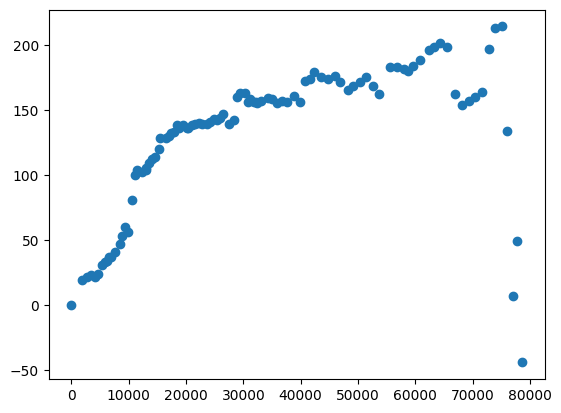

In [5]:
import matplotlib.pyplot as plt


plt.figure()

plt.scatter(df["distance"], df["height"])

plt.show()

In [ ]:
df["angle"] = (df["height"].shift(-1) - df["height"]) / (
    df["distance"].shift(-1) - df["distance"]
)

max_distance = df["distance"].max()
interpolated_heights = []
distances = []

curr_distance = 0
last_ref_distance_index = 0
while curr_distance < max_distance:
    distances.append(curr_distance)
    if curr_distance >= df.iloc[last_ref_distance_index + 1]["distance"]:
        last_ref_distance_index += 1

    val = df.iloc[last_ref_distance_index]["height"] + df.iloc[last_ref_distance_index][
        "angle"
    ] * (curr_distance - df.iloc[last_ref_distance_index]["distance"])

    curr_distance += 250
    interpolated_heights.append(val)

In [10]:
interpolated_heights

[np.float64(0.0),
 np.float64(2.4851084831374273),
 np.float64(4.9702169662748545),
 np.float64(7.455325449412282),
 np.float64(9.940433932549709),
 np.float64(12.425542415687136),
 np.float64(14.910650898824564),
 np.float64(17.39575938196199),
 np.float64(19.318902428108302),
 np.float64(20.218591428904833),
 np.float64(21.118280429701365),
 np.float64(22.007114880376303),
 np.float64(22.363340950940643),
 np.float64(22.71956702150498),
 np.float64(22.91715565251755),
 np.float64(22.52778881754068),
 np.float64(22.138421982563813),
 np.float64(22.536983425751558),
 np.float64(23.37016862524618),
 np.float64(24.64684937762515),
 np.float64(27.297133081049655),
 np.float64(29.94741678447416),
 np.float64(31.706015222131263),
 np.float64(32.87716128596272),
 np.float64(33.44910154908684),
 np.float64(33.95082798606826),
 np.float64(36.33851278268756),
 np.float64(37.0),
 np.float64(37.36106451854986),
 np.float64(38.67057252864387),
 np.float64(39.98008053873789),
 np.float64(41.4059293

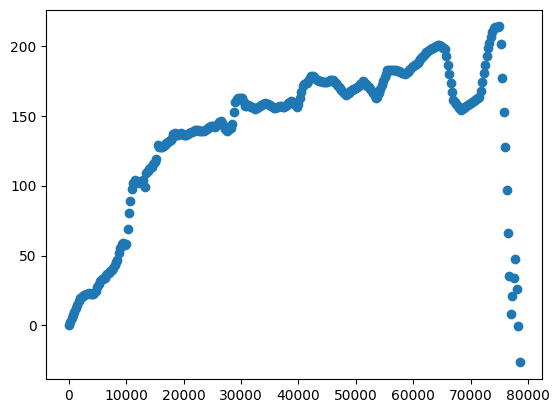

In [11]:
plt.figure()
plt.scatter(distances, interpolated_heights)
plt.show()

In [20]:
# save distances and interpolated_heights to csv

# Save as tab-separated values (TSV)
np.savetxt(
    "../data/interpolated_heights.txt",
    np.column_stack([distances, interpolated_heights]),
    delimiter="\t",
    header="distance\theight",
    comments="",
)

In [21]:
results


,distance,x,R
0,0.0,0.0,40.0
1,250.0,0.0,140.0
2,500.0,1.0,300.0
3,750.0,0.0,140.0
4,1000.0,0.0,40.0
...,...,...,...
310,77500.0,0.0,140.0
311,77750.0,1.0,300.0
312,78000.0,0.0,140.0
313,78250.0,0.0,40.0


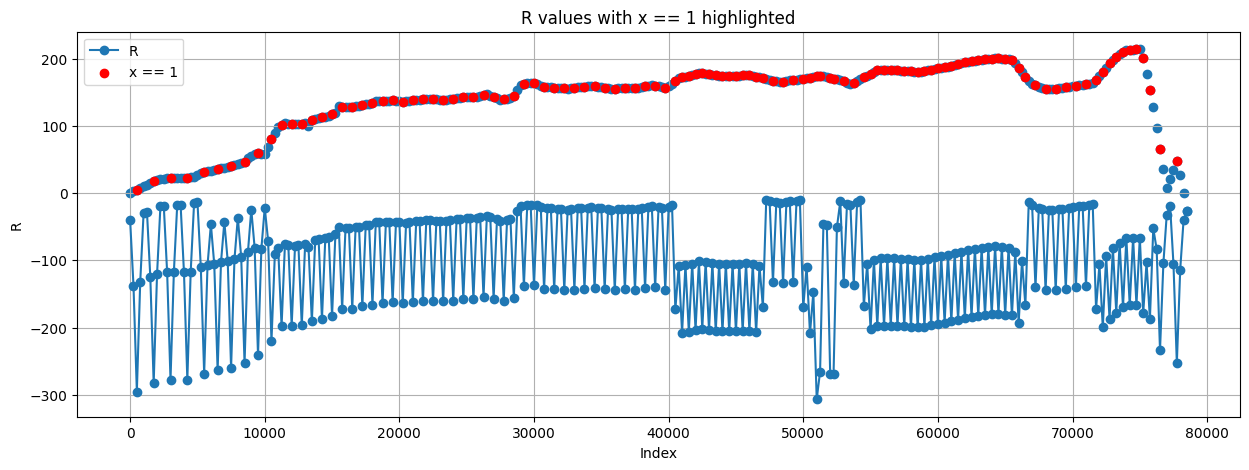

In [ ]:
# Load the results from Julia and plot
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("../data/solution_results.txt", sep="\t")

plt.figure(figsize=(15, 5))
plt.plot(
    results["distance"], interpolated_heights - results["R"], label="R", marker="o"
)

# Mark where x == 1
selected = results[results["x"] == 1]

selected_heights = np.array(interpolated_heights)[results["x"] == 1]
plt.scatter(
    selected["distance"], selected_heights, color="red", label="x == 1", zorder=5
)
plt.scatter(distances, interpolated_heights)

plt.xlabel("Index")
plt.ylabel("R")
plt.title("R values with x == 1 highlighted")
plt.legend()
plt.grid(True)
plt.show()

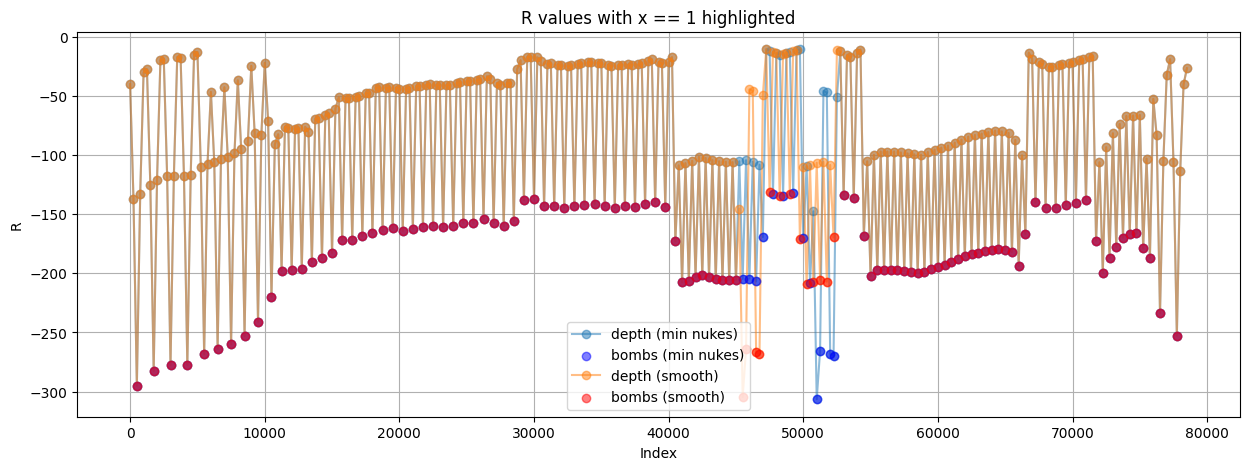

In [17]:
# Load the results from Julia and plot
import pandas as pd
import matplotlib.pyplot as plt


plt.figure(figsize=(15, 5))


results = pd.read_csv("../data/solution_results.txt", sep="\t")
depth = interpolated_heights - results["R"]  # R is removed dirt
plt.plot(results["distance"], depth, label="depth (min nukes)", marker="o", alpha=0.5)
selected = results[results["x"] == 1]
selected_heights = np.array(depth)[results["x"] == 1]
plt.scatter(
    selected["distance"],
    selected_heights,
    color="blue",
    label="bombs (min nukes)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.5,
)

results = pd.read_csv("../data/smooth_solution_results.txt", sep="\t")
depth = interpolated_heights - results["R"]  # R is removed dirt
plt.plot(results["distance"], depth, label="depth (smooth)", marker="o", alpha=0.5)

# Mark where x == 1
selected = results[results["x"] == 1]

selected_heights = np.array(depth)[results["x"] == 1]
plt.scatter(
    selected["distance"],
    selected_heights,
    color="red",
    label="bombs (smooth)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.5,
)
# plt.scatter(distances, interpolated_heights)

plt.xlabel("Index")
plt.ylabel("R")
plt.title("R values with x == 1 highlighted")
plt.legend()
plt.grid(True)
plt.show()

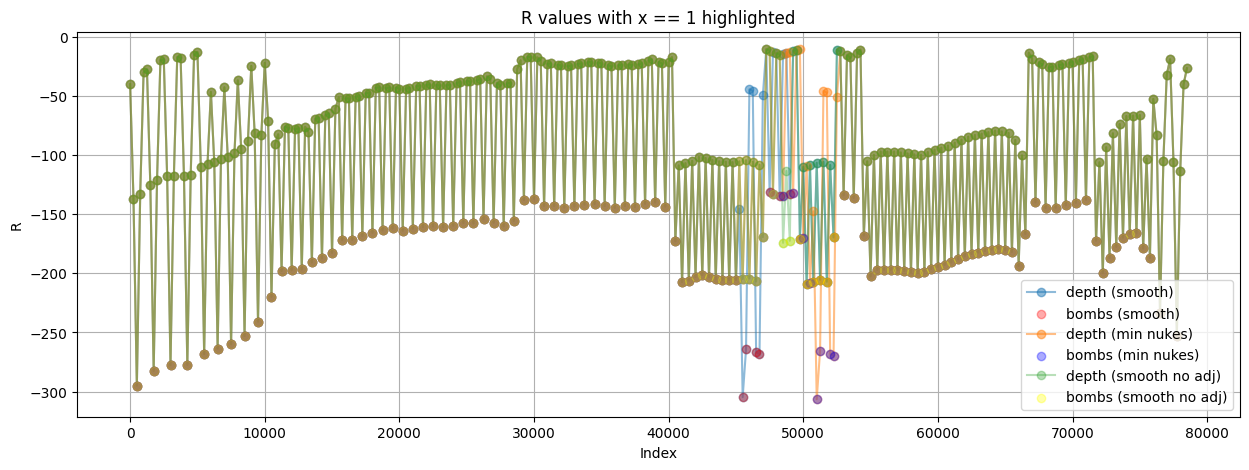

In [16]:
# Load the results from Julia and plot
import pandas as pd
import matplotlib.pyplot as plt


plt.figure(figsize=(15, 5))
results = pd.read_csv("../data/smooth_solution_results.txt", sep="\t")
depth = interpolated_heights - results["R"]  # R is removed dirt
plt.plot(results["distance"], depth, label="depth (smooth)", marker="o", alpha=0.5)

# Mark where x == 1
selected = results[results["x"] == 1]

selected_heights = np.array(depth)[results["x"] == 1]
plt.scatter(
    selected["distance"],
    selected_heights,
    color="red",
    label="bombs (smooth)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.33,
)
# plt.scatter(distances, interpolated_heights)
results = pd.read_csv("../data/solution_results.txt", sep="\t")
depth = interpolated_heights - results["R"]  # R is removed dirt
plt.plot(results["distance"], depth, label="depth (min nukes)", marker="o", alpha=0.5)
selected = results[results["x"] == 1]
selected_heights = np.array(depth)[results["x"] == 1]
plt.scatter(
    selected["distance"],
    selected_heights,
    color="blue",
    label="bombs (min nukes)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.33,
)

results = pd.read_csv("../data/smooth_no_adj_solution_results.txt", sep="\t")
depth = interpolated_heights - results["R"]  # R is removed dirt
plt.plot(
    results["distance"], depth, label="depth (smooth no adj)", marker="o", alpha=0.33
)
selected = results[results["x"] == 1]
selected_heights = np.array(depth)[results["x"] == 1]
plt.scatter(
    selected["distance"],
    selected_heights,
    color="yellow",
    label="bombs (smooth no adj)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.33,
)


plt.xlabel("Index")
plt.ylabel("R")
plt.title("R values with x == 1 highlighted")
plt.legend()
plt.grid(True)
plt.show()

### Dial a yield - is it worth it?

In [ ]:
# below is only for the first 250 entries, otherwise solver runs >10 min.

In [27]:
result

NameError: name 'result' is not defined

In [34]:
results[(results["x1"] == 1) | (results["x2"] == 1)]

,distance,x1,x2,R
2,500.0,1.0,0.0,300.0
7,1750.0,1.0,0.0,300.0
12,3000.0,1.0,0.0,300.0
17,4250.0,1.0,0.0,300.0
22,5500.0,1.0,0.0,300.0
...,...,...,...,...
236,59000.0,1.0,0.0,300.0
239,59750.0,0.0,1.0,500.0
242,60500.0,1.0,0.0,300.0
245,61250.0,0.0,1.0,500.0


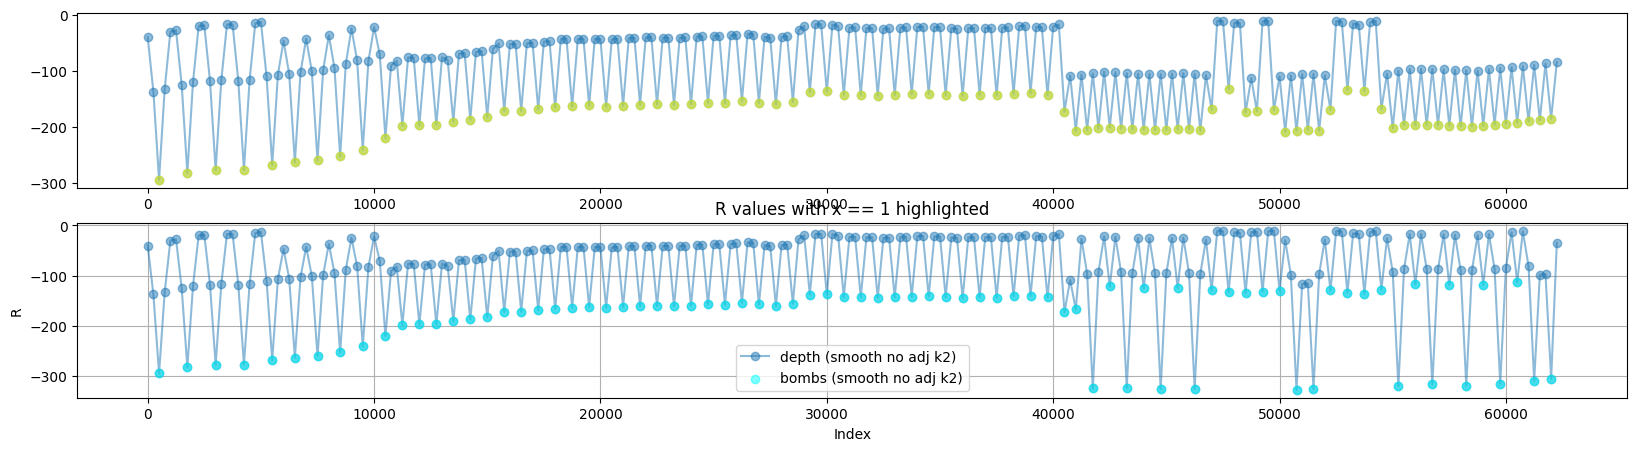

In [42]:
# Load the results from Julia and plot
import pandas as pd
import matplotlib.pyplot as plt

entries = 250


# plt.figure(figsize=(15, 5))
# subplots
fig, axs = plt.subplots(2, 1, figsize=(20, 5))

results = pd.read_csv("../data/smooth_no_adj_solution_results.txt", sep="\t")
results = results[:entries]
ih = np.array(interpolated_heights)[:entries]
depth = ih - results["R"]  # R is removed dirt
axs[0].plot(
    results["distance"], depth, label="depth (smooth no adj)", marker="o", alpha=0.5
)
selected = results[results["x"] == 1]
selected_heights = np.array(depth)[results["x"] == 1]
axs[0].scatter(
    selected["distance"],
    selected_heights,
    color="yellow",
    label="bombs (smooth no adj)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.5,
)

results = pd.read_csv(
    "../data/smooth_no_adj_dial_k2_solution_results_250.txt", sep="\t"
)
# results = results[:entries]
ih = np.array(interpolated_heights)[:entries]
depth = ih - results["R"]  # R is removed dirt
axs[1].plot(
    results["distance"], depth, label="depth (smooth no adj k2)", marker="o", alpha=0.5
)
selected = results[(results["x1"] == 1) | (results["x2"] == 1)]
selected_heights = np.array(depth)[(results["x1"] == 1) | (results["x2"] == 1)]
axs[1].scatter(
    selected["distance"],
    selected_heights,
    color="cyan",
    label="bombs (smooth no adj k2)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.5,
)


plt.xlabel("Index")
plt.ylabel("R")
plt.title("R values with x == 1 highlighted")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
results

,distance,x1,x2,R
0,0.0,0.0,0.0,40.0
1,250.0,0.0,0.0,140.0
2,500.0,1.0,0.0,300.0
3,750.0,0.0,0.0,140.0
4,1000.0,0.0,0.0,40.0
...,...,...,...,...
245,61250.0,0.0,1.0,500.0
246,61500.0,0.0,0.0,290.0
247,61750.0,0.0,0.0,290.0
248,62000.0,0.0,1.0,500.0
